In [1]:
import rasterio
import numpy as np
import xarray as xr
import rioxarray as rxr
from pathlib import Path
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy.feature as cfeature

In [2]:
# path to raster file
file_path = '/home/mgurazada/enso_compound_extremes/data/Global_cropland_3km_2019.tif'

# open the raster file
with rasterio.open(file_path) as src:
    # read raster data as a NumPy array
    croplands = src.read(1)  # use `read(1)` for a single-band raster, adjust the band number if needed

    # Get metadata information
    metadata = src.meta

In [3]:
croplands

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(5200, 14000), dtype=uint8)

In [4]:
metadata

{'driver': 'GTiff',
 'dtype': 'uint8',
 'nodata': None,
 'width': 14000,
 'height': 5200,
 'count': 1,
 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'),
 'transform': Affine(0.025000000000000053, 0.0, -170.0,
        0.0, -0.025000000000000053, 70.0)}

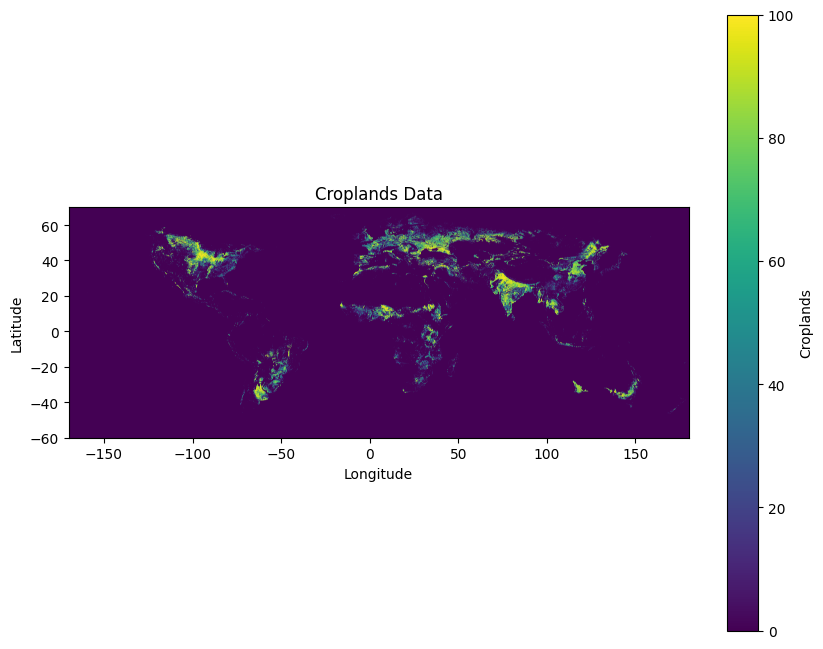

In [5]:
# Plot the croplands data
plt.figure(figsize=(10, 8))
plt.imshow(croplands, cmap='viridis', extent=[metadata['transform'][2], metadata['transform'][2] + metadata['width'] * metadata['transform'][0],
                                                  metadata['transform'][5] + metadata['height'] * metadata['transform'][4], metadata['transform'][5]])
plt.colorbar(label='Croplands')
plt.title('Croplands Data')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

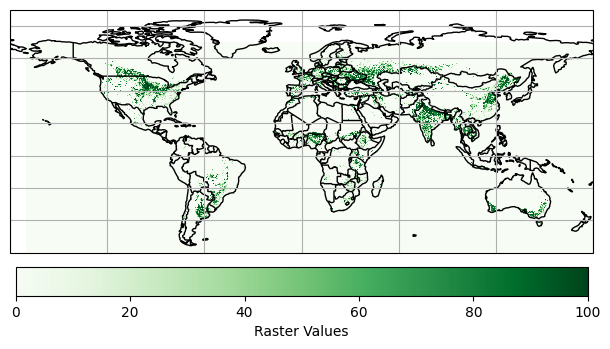

In [6]:
# Calculate aspect ratio
aspect_ratio = metadata['width'] / metadata['height']

# Set the figure size based on the aspect ratio
fig, ax = plt.subplots(figsize=(10, 10 / aspect_ratio), subplot_kw={'projection': ccrs.PlateCarree()})

# Plot the raster data with the correct extent and crs, using the reversed Greens colormap
c = ax.imshow(croplands, extent=[metadata['transform'][2], metadata['transform'][2] + metadata['width'] * metadata['transform'][0],
                                 metadata['transform'][5] + metadata['height'] * metadata['transform'][4], metadata['transform'][5]],
              origin='upper', cmap='Greens', interpolation='nearest', transform=ccrs.PlateCarree())

# Invert the y-axis to correct the plot
ax.invert_yaxis()

countries = cfeature.BORDERS
ax.add_feature(countries, linewidth=1, edgecolor='black')

# Add coastlines and gridlines
ax.set_extent([-182, 180, -60, 90], ccrs.PlateCarree())
ax.coastlines(linewidth=1, color='black')
ax.gridlines()

# Add colorbar
cbar = plt.colorbar(c, ax=ax, orientation='horizontal', fraction=0.1, pad=0.05)
cbar.set_label('Raster Values')

# Show the plot
plt.show()

In [7]:
croplands_path = '/home/mgurazada/enso_compound_extremes/data/Global_cropland_3km_2019.tif'
# Open the croplands GeoTIFF file using rasterio
croplands = rasterio.open(croplands_path)

In [8]:
# Print the resolution of croplands data
croplands_resolution_x = croplands.transform[0]
croplands_resolution_y = croplands.transform[4]

print(f"Resolution of croplands data in X direction: {croplands_resolution_x} units")
print(f"Resolution of croplands data in Y direction: {croplands_resolution_y} units")

Resolution of croplands data in X direction: 0.025000000000000053 units
Resolution of croplands data in Y direction: -0.025000000000000053 units


In [9]:
# print the number of grid cells in croplands data
num_grid_cells_x = croplands.width
num_grid_cells_y = croplands.height

print(f"Number of grid cells in croplands data (X direction): {num_grid_cells_x}")
print(f"Number of grid cells in croplands data (Y direction): {num_grid_cells_y}")
print(f"Total number of grid cells in croplands data: {num_grid_cells_x * num_grid_cells_y}")

Number of grid cells in croplands data (X direction): 14000
Number of grid cells in croplands data (Y direction): 5200
Total number of grid cells in croplands data: 72800000


In [11]:
tif_path = Path("/home/mgurazada/enso_compound_extremes/data/Global_cropland_3km_2019.tif")
nc_path  = Path("/home/mgurazada/snowdroughts_thirst/data/cropland/Global_cropland_3km_2019.nc")

# open GeoTIFF as DataArray
da = rxr.open_rasterio(tif_path, masked=True)  # dims: ('band', 'y', 'x')

# drop the band dim (only 1 band)
da = da.squeeze("band", drop=True)

# give it a nice variable name
da.name = "cropland"

# optional: add attributes
da.attrs["long_name"] = "Global cropland extent"
da.attrs["units"] = "fraction or mask (check source metadata)"

# save to NetCDF
ds = da.to_dataset()
ds.to_netcdf(nc_path)

print("Saved to:", nc_path)

Saved to: /home/mgurazada/snowdroughts_thirst/data/cropland/Global_cropland_3km_2019.nc


/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3699: SerializationWarning: saving variable cropland with floating point data as an integer dtype without any _FillValue to use for NaNs
  exec(code_obj, self.user_global_ns, self.user_ns)


In [12]:
ds = xr.open_dataset(nc_path)
cropland = ds["cropland"]

# if rioxarray kept georeferencing:
if hasattr(cropland, "rio"):
    print("Resolution (x, y):", cropland.rio.resolution())

Resolution (x, y): (0.025000000000000053, -0.025000000000000053)


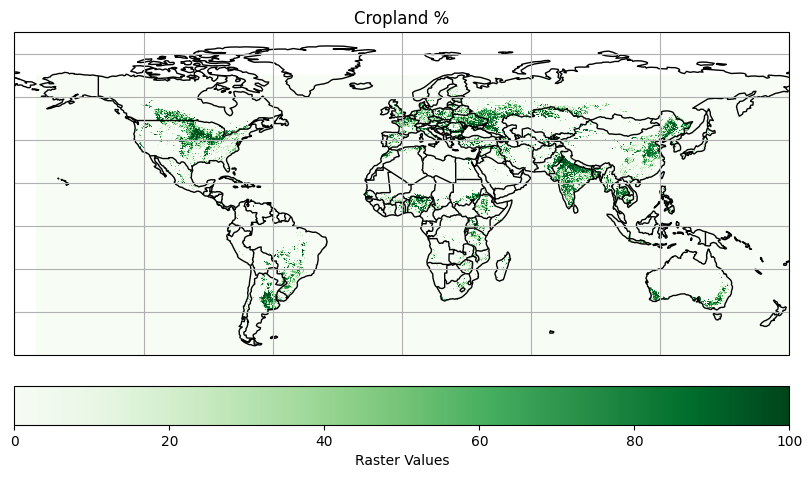

In [13]:
# create a map projection using PlateCarree
projection = ccrs.PlateCarree()

# create a figure and axis
fig, ax = plt.subplots(subplot_kw={'projection': projection}, figsize=(10, 8))

# plot the data using pcolormesh
c = cropland.plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), cmap='Greens', add_colorbar=False)

# set the extent
ax.set_extent([-182, 180, -60, 90], ccrs.PlateCarree())
ax.coastlines(linewidth=1, color='black')
ax.gridlines()
countries = cfeature.BORDERS
ax.add_feature(countries, linewidth=1, edgecolor='black')

# add a colorbar
cbar = plt.colorbar(c, ax=ax, orientation='horizontal', pad=0.05)
cbar.set_label('Raster Values')  # Replace 'Variable Units' with the actual units of your variable

# set the title
plt.title('Cropland %')

# show the plot
plt.show()